# Content classification — honest (leak-free) analysis

**Finding:** this dataset does **not** support solid/water/empty classification.
This notebook shows *why*, correctly:
1. a **temporal confound** (classes were recorded in time-blocks → recording time predicts the label);
2. a **leak-free time split** → accuracy collapses to ~baseline;
3. **mass regression** → r≈0, R²<0 (no monotonic payload signal).

The pipeline (`train_classifier.py`) is correct and reusable — the limitation is
data acquisition (4–5 Hz sampling, small payloads at low-moment-arm poses, and
non-interleaved recording order), not modeling.

In [1]:
import os, sys, glob, re
sys.path.insert(0, os.path.abspath('..'))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import pearsonr
from sklearn.model_selection import StratifiedKFold, cross_val_score, KFold
from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
import train_classifier as tc

recs = tc.load_all()                      # (tsec, class, feature_vector) per recording
t  = np.array([r[0] for r in recs]).reshape(-1,1)
y  = np.array([r[1] for r in recs])
X  = np.array([r[2] for r in recs])
print(f'{len(recs)} recordings, classes {sorted(set(y))}')

110 recordings, classes [np.str_('empty'), np.str_('solid'), np.str_('water')]


## 1. The temporal confound — recording *time* predicts the class

In [2]:
fmt = lambda s: f'{s//3600:02d}:{(s%3600)//60:02d}'
for c in sorted(set(y)):
    ts = sorted(t[y==c].ravel()); print(f'  {c:6} n={len(ts):2d}  {fmt(ts[0])}..{fmt(ts[-1])}')
order = ''.join({'empty':'E','solid':'S','water':'W'}[c] for _,c,_ in sorted(recs))
print('  class order over time:', order)
cv = StratifiedKFold(5, shuffle=True, random_state=42)
f1_time = cross_val_score(RandomForestClassifier(200,max_depth=4,random_state=0), t, y, cv=cv, scoring='f1_macro').mean()
print(f'\n  classifier using ONLY recording-time: CV macro-F1 = {f1_time:.3f}  <-- ~1.0 means the label leaks through time')

  empty  n=17  18:02..18:18
  solid  n=46  18:19..19:30
  water  n=47  18:41..19:49
  class order over time: EEEEEEEEEEEEEEEEESSSSSSSSSSSSSSSSSSSSSSSSSWWWWWWWWWWWWWWWWWWWWWWWWWWWWWWWWWWWWWWWSSSSSSSSSSSSSSSSSSSSSWWWWWWWW



  classifier using ONLY recording-time: CV macro-F1 = 1.000  <-- ~1.0 means the label leaks through time


## 2. Leak-free evaluation (within-class earliest→train, latest→test)

CV macro-F1: {'logreg': np.float64(0.449), 'svc': np.float64(0.414), 'rf': np.float64(0.394), 'gb': np.float64(0.292)}  best= logreg
LEAK-FREE test: acc=0.333  macro-F1=0.260  baseline=0.199  delta=+0.062


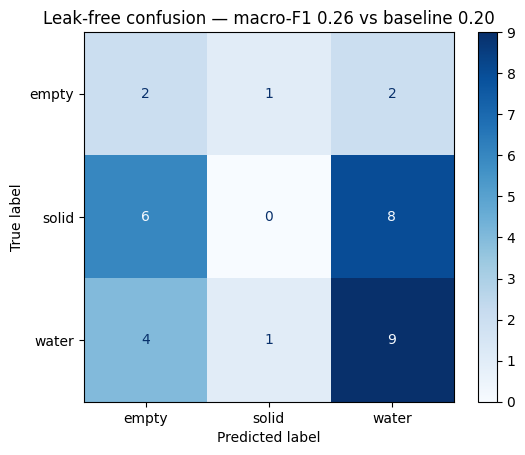

In [3]:
Xtr, ytr, Xte, yte = tc.time_honest_split(recs)
classes = sorted(set(ytr))
scored = {n: cross_val_score(p, Xtr, ytr, cv=cv, scoring='f1_macro').mean() for n,p in tc.make_models().items()}
best = max(scored, key=scored.get)
pipe = tc.make_models(best)[best].fit(Xtr, ytr); pred = pipe.predict(Xte)
f1m  = f1_score(yte, pred, average='macro')
base = f1_score(yte, DummyClassifier(strategy='most_frequent').fit(Xtr,ytr).predict(Xte), average='macro')
print('CV macro-F1:', {k:round(v,3) for k,v in scored.items()}, ' best=', best)
print(f'LEAK-FREE test: acc={accuracy_score(yte,pred):.3f}  macro-F1={f1m:.3f}  baseline={base:.3f}  delta={f1m-base:+.3f}')
ConfusionMatrixDisplay(confusion_matrix(yte,pred,labels=classes), display_labels=classes).plot(cmap='Blues')
plt.title(f'Leak-free confusion — macro-F1 {f1m:.2f} vs baseline {base:.2f}'); plt.show()

## 3. Mass regression — is there *any* monotonic signal? (the clincher)

In [4]:
def trimmed(x,p=0.1):
    x=np.sort(np.asarray(x,float)); k=int(len(x)*p); return np.mean(x[k:len(x)-k]) if len(x)-2*k>0 else np.mean(x)
def grams(l):
    if 'empty' in l: return 0.0
    m=re.search(r'(\d+)(g|pct)', l); return float(m.group(1)) if m else np.nan
rows=[]
for p in sorted(glob.glob('../recordings/recording_*.csv')):
    df=pd.read_csv(p); l=str(df['object_label'].iloc[0])
    h=df[df['phase']=='TRAVEL_STABLE_HOLD']['tau3_nm'].values
    if len(h)<3: h=df[df['phase'].astype(str).str.contains('TRAVEL')]['tau3_nm'].values
    rows.append({'cls':tc.to_3class(l),'g':grams(l),'j3':trimmed(h)})
d=pd.DataFrame(rows)
for mat,key in [('solid (grams)', d.cls=='solid'), ('water (pct)', d.cls=='water')]:
    s=d[key].dropna(subset=['g'])
    r,pv=pearsonr(s['g'], s['j3'])
    r2=cross_val_score(make_pipeline(StandardScaler(),RandomForestRegressor(200,random_state=0)), s[['j3']].values, s['g'].values, cv=KFold(5,shuffle=True,random_state=0), scoring='r2').mean()
    print(f'  {mat:14}  Pearson r={r:+.2f} (p={pv:.2f})   CV R^2={r2:+.3f}   -> {"signal" if abs(r)>0.4 and r2>0.1 else "NO monotonic signal"}')

  solid (grams)   Pearson r=-0.16 (p=0.29)   CV R^2=-0.882   -> NO monotonic signal


  water (pct)     Pearson r=+0.09 (p=0.58)   CV R^2=-0.184   -> NO monotonic signal


## Conclusion
- **Temporal confound:** recording time alone predicts class at ~100% → any random/label-stratified split is contaminated.
- **Leak-free:** collapses to ~baseline (note `solid` recall is ~0 — it isn't really classifying).
- **Mass regression:** r≈0, R²<0 → **no monotonic payload signal to recover** (not even by better filtering).

**This is a data-acquisition limit, not a modeling one.** To make it work:
1. **Interleave recording order** (empty/solid/water mixed in time) — removes the confound, free.
2. **Cantilever grasp pose** (larger moment arm → payload torque above the noise floor).
3. **100 Hz on-robot capture** (`control_service.py`) — exposes slosh/rattle dynamics.

What *does* work with current hardware: **coarse load sensing** (a ~1.4 kg payload gives a clean −6 N·m shift on J3).